In [ ]:

# Step 1: Install libraries and initialize the environment

!pip -q install opencv-python-headless pandas matplotlib

# Import required libraries
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive, files
from IPython.display import display

print("=" * 70)
print("SATELLITE IMAGE SEGMENTATION PROJECT")
print("=" * 70)

print("TensorFlow Version:", tf.__version__)
print("OpenCV Version:", cv2.__version__)

# Connect Google Drive
drive.mount('/content/drive')

print("\nGoogle Drive connected successfully!")


SATELLITE IMAGE SEGMENTATION PROJECT
TensorFlow Version: 2.21.0
OpenCV Version: 5.0.0
Mounted at /content/drive

Google Drive connected successfully!


In [ ]:

# Step 2: Load project configuration

# Define project directories
PROJECT_DIR = "/content/drive/MyDrive/Satellite-Image-Project"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
CONFIG_DIR = os.path.join(PROJECT_DIR, "config")
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")

# Load project configuration
with open(
    os.path.join(CONFIG_DIR, "project_config.json"),
    "r"
) as file:
    project_config = json.load(file)

# Load class mappings
with open(
    os.path.join(CONFIG_DIR, "class_mapping.json"),
    "r"
) as file:
    class_mapping = json.load(file)

# Restore model configuration
IMAGE_SIZE = project_config["image_size"]
NUM_CLASSES = project_config["num_classes"]

class_names = class_mapping["class_names"]

id_to_color = {
    int(k): tuple(v)
    for k, v in class_mapping["id_to_color"].items()
}

color_to_id = {
    tuple(map(int, k.strip("()").split(","))): int(v)
    for k, v in class_mapping["color_to_id"].items()
}

# Display configuration
print("=" * 70)
print("PROJECT CONFIGURATION LOADED")
print("=" * 70)

print("Project:", project_config["project_name"])
print("Selected Model:", project_config["selected_model"])
print("Image Size:", IMAGE_SIZE)
print("Number of Classes:", NUM_CLASSES)

print("\nLand-cover classes:")

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print("\nConfiguration loaded successfully!")


PROJECT CONFIGURATION LOADED
Project: Automated Satellite Image Enhancement and Land-Cover Segmentation System
Selected Model: Experimental U-Net
Image Size: 256
Number of Classes: 7

Land-cover classes:
0: urban_land
1: agriculture_land
2: rangeland
3: forest_land
4: water
5: barren_land
6: unknown

Configuration loaded successfully!


In [ ]:

# Step 3: Load the saved Experimental U-Net

FINAL_MODEL_PATH = project_config["model_path"]

# Verify model availability
if not os.path.exists(FINAL_MODEL_PATH):
    raise FileNotFoundError(
        f"Trained model not found: {FINAL_MODEL_PATH}"
    )

# Load the trained model
best_experimental_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

print("=" * 70)
print("EXPERIMENTAL U-NET LOADED SUCCESSFULLY")
print("=" * 70)

print("Model:", project_config["selected_model"])
print("Model location:", FINAL_MODEL_PATH)
print("Input shape:", best_experimental_model.input_shape)
print("Output shape:", best_experimental_model.output_shape)

print("\nNo model training was performed.")


EXPERIMENTAL U-NET LOADED SUCCESSFULLY
Model: Experimental U-Net
Model location: /content/drive/MyDrive/Satellite-Image-Project/models/final_rangeland_experimental_unet.keras
Input shape: (None, 256, 256, 3)
Output shape: (None, 256, 256, 7)

No model training was performed.


In [ ]:

# # Download DeepGlobe dataset into the current Colab runtime

# !pip install -q kagglehub

# import kagglehub
# import os

# DATASET_PATH = kagglehub.dataset_download(
#     "balraj98/deepglobe-land-cover-classification-dataset"
# )

# print("Dataset downloaded successfully!")
# print("Dataset location:", DATASET_PATH)


100%|██████████| 2.74G/2.74G [00:41<00:00, 71.7MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/balraj98/deepglobe-land-cover-classification-dataset/versions/2


In [ ]:

# import glob
# import os

# satellite_images = sorted(
#     glob.glob(
#         os.path.join(DATASET_PATH, "**", "*_sat.jpg"),
#         recursive=True
#     )
# )

# image_mask_pairs = []

# for image_path in satellite_images:

#     mask_path = image_path.replace("_sat.jpg", "_mask.png")

#     if os.path.exists(mask_path):
#         image_mask_pairs.append((image_path, mask_path))

# print("Satellite images found:", len(satellite_images))
# print("Complete image-mask pairs:", len(image_mask_pairs))

# if image_mask_pairs:
#     print("\nFirst image:", image_mask_pairs[0][0])
#     print("First mask:", image_mask_pairs[0][1])


Satellite images found: 1146
Complete image-mask pairs: 803

First image: /root/.cache/kagglehub/datasets/balraj98/deepglobe-land-cover-classification-dataset/versions/2/train/100694_sat.jpg
First mask: /root/.cache/kagglehub/datasets/balraj98/deepglobe-land-cover-classification-dataset/versions/2/train/100694_mask.png


In [ ]:

# import zipfile
# from google.colab import files

# DOWNLOAD_COUNT = 50

# ZIP_PATH = "/content/deepglobe_validation_samples.zip"

# selected_pairs = image_mask_pairs[:DOWNLOAD_COUNT]

# with zipfile.ZipFile(
#     ZIP_PATH,
#     "w",
#     zipfile.ZIP_DEFLATED
# ) as zip_file:

#     for image_path, mask_path in selected_pairs:

#         zip_file.write(
#             image_path,
#             arcname="satellite_images/" + os.path.basename(image_path)
#         )

#         zip_file.write(
#             mask_path,
#             arcname="ground_truth_masks/" + os.path.basename(mask_path)
#         )

# print("ZIP created successfully!")
# print("Image-mask pairs:", len(selected_pairs))
# print("Total files:", len(selected_pairs) * 2)

# files.download(ZIP_PATH)


ZIP created successfully!
Image-mask pairs: 50
Total files: 100


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Step 4: Define satellite image preprocessing function

def preprocess_satellite_image(image_path):

    # Read original image
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(
            f"Unable to read image: {image_path}"
        )

    # Convert BGR to RGB
    original_image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Resize image to 256 x 256
    resized_image = cv2.resize(
        original_image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_LINEAR
    )

    # Apply Gaussian Blur
    blurred_image = cv2.GaussianBlur(
        resized_image,
        (5, 5),
        0
    )

    # Convert RGB to LAB
    lab_image = cv2.cvtColor(
        blurred_image,
        cv2.COLOR_RGB2LAB
    )

    # Apply CLAHE to the L channel
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    lab_image[:, :, 0] = clahe.apply(
        lab_image[:, :, 0]
    )

    # Convert LAB back to RGB
    enhanced_image = cv2.cvtColor(
        lab_image,
        cv2.COLOR_LAB2RGB
    )

    # Normalize pixel values
    normalized_image = (
        enhanced_image.astype(np.float32) / 255.0
    )

    return (
        original_image,
        enhanced_image,
        normalized_image
    )


print("Satellite image preprocessing function defined successfully!")
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Enhancement: Gaussian Blur + CLAHE")
print("Normalization: 0 to 1")


Satellite image preprocessing function defined successfully!
Image size: 256 x 256
Enhancement: Gaussian Blur + CLAHE
Normalization: 0 to 1


In [ ]:

# Step 5: Upload a satellite image from your computer

print("=" * 70)
print("SATELLITE IMAGE UPLOAD")
print("=" * 70)

# Upload image
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded.")

# Get uploaded image filename
uploaded_filename = next(iter(uploaded))

# Store image path
selected_image_path = os.path.abspath(
    uploaded_filename
)

# Verify image
if not os.path.exists(selected_image_path):
    raise FileNotFoundError(
        f"Image not found: {selected_image_path}"
    )

print("\nImage uploaded successfully!")
print("Filename:", uploaded_filename)
print("Image path:", selected_image_path)


SATELLITE IMAGE UPLOAD


Saving 119_sat.jpg to 119_sat.jpg

Image uploaded successfully!
Filename: 119_sat.jpg
Image path: /content/119_sat.jpg


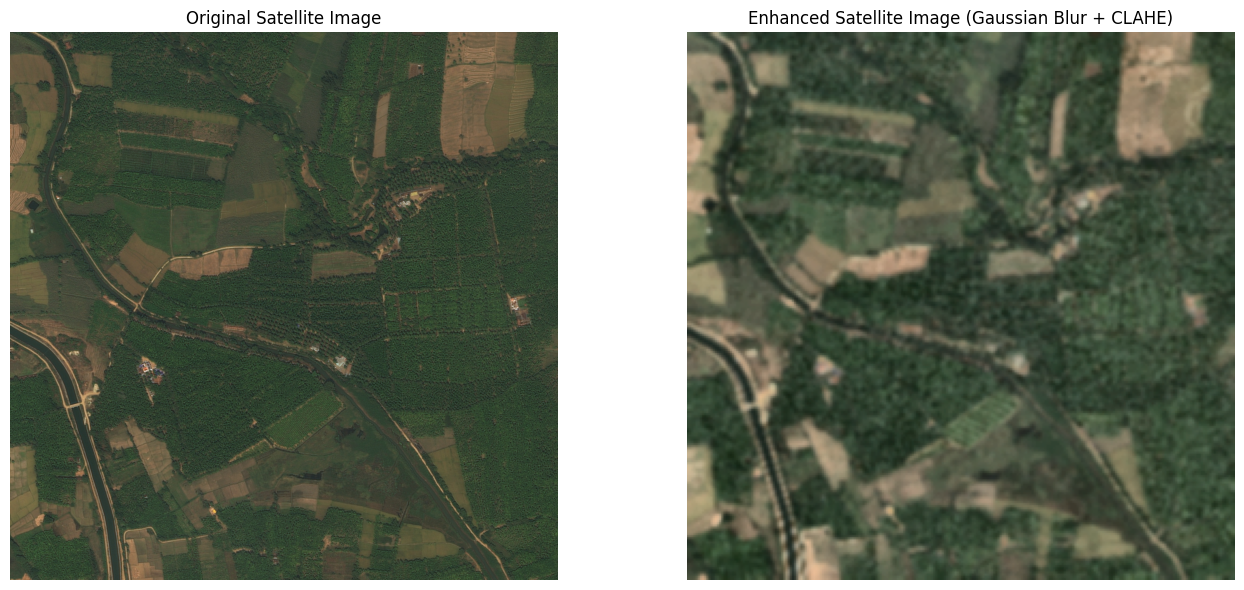

IMAGE ENHANCEMENT COMPLETED
Original image shape: (2448, 2448, 3)
Enhanced image shape: (256, 256, 3)
Model input shape: (256, 256, 3)
Normalized pixel range: 0.07450981 to 0.91764706

Image enhancement completed successfully!


In [ ]:

# Step 6: Apply image enhancement and display results

# Preprocess uploaded satellite image
original_image, enhanced_image, model_input = preprocess_satellite_image(
    selected_image_path
)

# Display original and enhanced images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image)
plt.title("Enhanced Satellite Image (Gaussian Blur + CLAHE)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Display image information
print("=" * 70)
print("IMAGE ENHANCEMENT COMPLETED")
print("=" * 70)

print("Original image shape:", original_image.shape)
print("Enhanced image shape:", enhanced_image.shape)
print("Model input shape:", model_input.shape)
print("Normalized pixel range:",
      model_input.min(), "to", model_input.max())

print("\nImage enhancement completed successfully!")


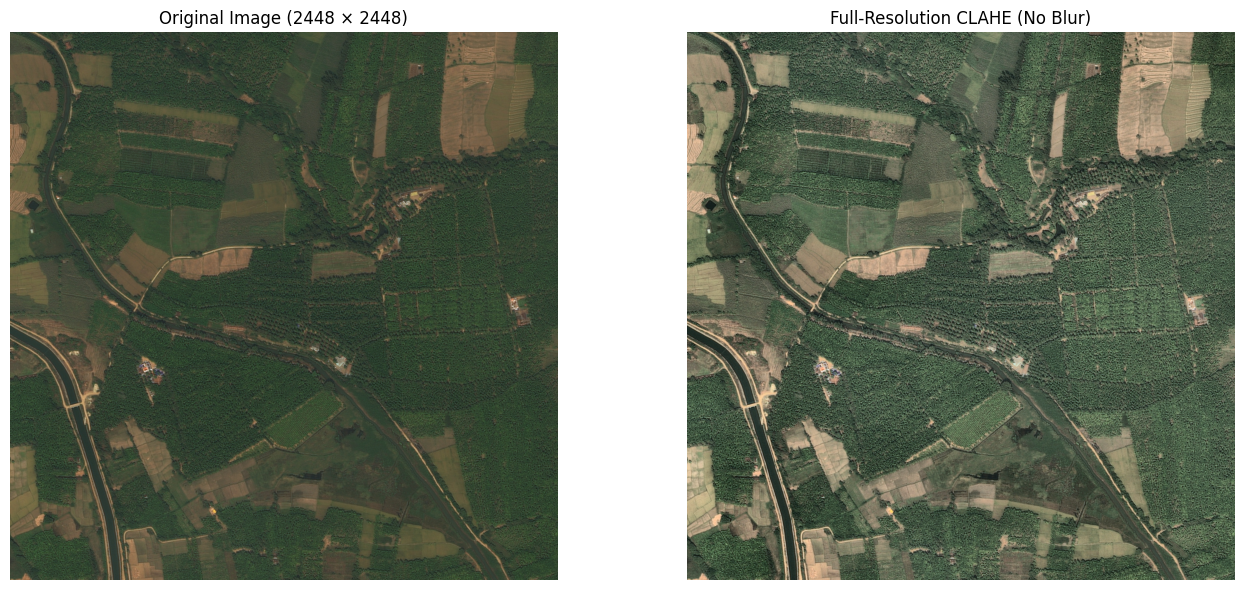

FULL-RESOLUTION ENHANCEMENT COMPLETED
Original shape: (2448, 2448, 3)
Enhanced shape: (2448, 2448, 3)
Saved at: /content/drive/MyDrive/Satellite-Image-Project/reports/485061_sat_enhanced.png


In [ ]:

# Step 7: Create full-resolution enhancement without Gaussian Blur

# Convert original image to LAB
original_lab = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2LAB
)

# Create CLAHE
visual_clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

# Enhance only the L channel
original_lab[:, :, 0] = visual_clahe.apply(
    original_lab[:, :, 0]
)

# Convert back to RGB
full_resolution_enhanced = cv2.cvtColor(
    original_lab,
    cv2.COLOR_LAB2RGB
)

# Save enhanced image in original resolution
enhanced_output_path = os.path.join(
    PROJECT_DIR,
    "reports",
    "485061_sat_enhanced.png"
)

cv2.imwrite(
    enhanced_output_path,
    cv2.cvtColor(
        full_resolution_enhanced,
        cv2.COLOR_RGB2BGR
    )
)

# Display comparison
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image (2448 × 2448)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(full_resolution_enhanced)
plt.title("Full-Resolution CLAHE (No Blur)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("=" * 70)
print("FULL-RESOLUTION ENHANCEMENT COMPLETED")
print("=" * 70)

print("Original shape:", original_image.shape)
print("Enhanced shape:", full_resolution_enhanced.shape)
print("Saved at:", enhanced_output_path)


In [ ]:

# Step 8: Perform land-cover segmentation using Experimental U-Net

# Prepare model input
model_input_batch = np.expand_dims(
    model_input,
    axis=0
)

# Generate segmentation predictions
predictions = best_experimental_model.predict(
    model_input_batch,
    verbose=1
)

# Convert probabilities into class IDs
predicted_mask = np.argmax(
    predictions[0],
    axis=-1
)

print("=" * 70)
print("LAND-COVER SEGMENTATION COMPLETED")
print("=" * 70)

print("Prediction shape:", predictions.shape)
print("Predicted mask shape:", predicted_mask.shape)
print("Detected classes:",
      np.unique(predicted_mask))

print("\nSegmentation prediction completed successfully!")


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
LAND-COVER SEGMENTATION COMPLETED
Prediction shape: (1, 256, 256, 7)
Predicted mask shape: (256, 256)
Detected classes: [0 1 2 3 4]

Segmentation prediction completed successfully!


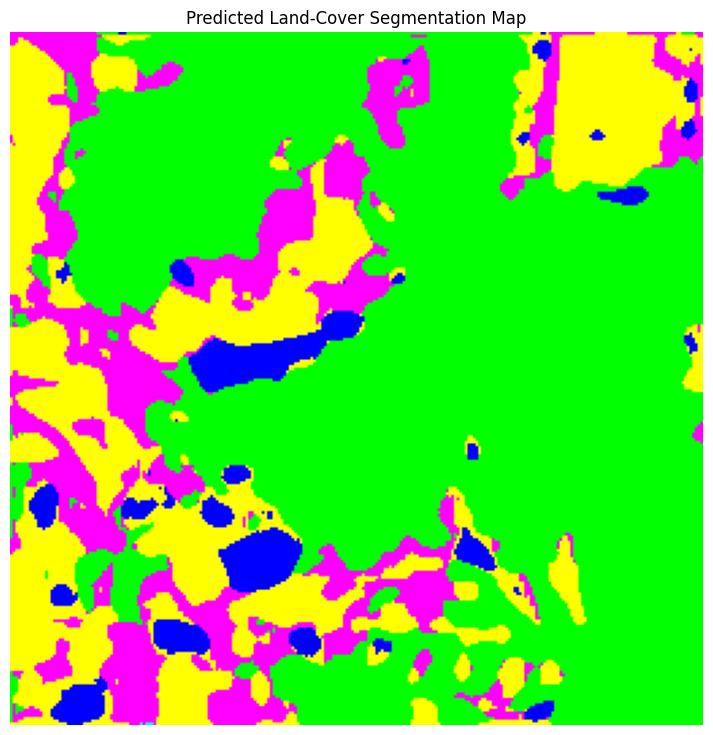

COLOURED SEGMENTATION MAP GENERATED
Segmentation map shape: (256, 256, 3)
Number of detected classes: 5
RGB colour mapping applied successfully!


In [ ]:

# Step 9: Generate coloured land-cover segmentation map

# Create an empty RGB segmentation image
segmentation_map = np.zeros(
    (IMAGE_SIZE, IMAGE_SIZE, 3),
    dtype=np.uint8
)

# Assign RGB colours to predicted classes
for class_id, color in id_to_color.items():

    segmentation_map[
        predicted_mask == class_id
    ] = color

# Display segmentation map
plt.figure(figsize=(9, 9))

plt.imshow(segmentation_map)
plt.title("Predicted Land-Cover Segmentation Map")
plt.axis("off")

plt.show()

print("=" * 70)
print("COLOURED SEGMENTATION MAP GENERATED")
print("=" * 70)

print("Segmentation map shape:", segmentation_map.shape)
print("Number of detected classes:", len(np.unique(predicted_mask)))
print("RGB colour mapping applied successfully!")


In [ ]:

# Step 10: Calculate land-cover distribution and image statistics

# Calculate total number of pixels
total_pixels = predicted_mask.size

# Prepare class-wise statistics
class_statistics = []

for class_id, class_name in enumerate(class_names):

    # Count pixels belonging to this class
    pixel_count = int(
        np.sum(predicted_mask == class_id)
    )

    # Calculate percentage
    percentage = (
        pixel_count / total_pixels
    ) * 100

    # Get corresponding RGB colour
    rgb_color = id_to_color[class_id]

    class_statistics.append({
        "Class ID": class_id,
        "Land-Cover Class": class_name,
        "Pixel Count": pixel_count,
        "Percentage (%)": round(percentage, 2),
        "RGB Color": str(rgb_color)
    })

# Create class distribution DataFrame
class_distribution_df = pd.DataFrame(
    class_statistics
)

# Calculate image quality statistics at equal resolution
resized_original = cv2.resize(
    original_image,
    (IMAGE_SIZE, IMAGE_SIZE),
    interpolation=cv2.INTER_LINEAR
)

def get_image_metrics(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    laplacian_variance = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    contrast = gray.std()
    brightness = gray.mean()

    return {
        "Sharpness (Laplacian Variance)": round(
            laplacian_variance, 3
        ),
        "Contrast (Standard Deviation)": round(
            contrast, 3
        ),
        "Mean Brightness": round(
            brightness, 3
        )
    }

image_metrics_df = pd.DataFrame([
    {
        "Image": "Resized Original",
        **get_image_metrics(resized_original)
    },
    {
        "Image": "Enhanced Model Input",
        **get_image_metrics(enhanced_image)
    }
])

# Display results
print("=" * 85)
print("LAND-COVER CLASS DISTRIBUTION")
print("=" * 85)

display(class_distribution_df)

print("\n" + "=" * 85)
print("IMAGE QUALITY STATISTICS")
print("=" * 85)

display(image_metrics_df.set_index("Image"))

print("\n" + "=" * 85)
print("SEGMENTATION SUMMARY")
print("=" * 85)

print("Original image dimensions:", original_image.shape)
print("Enhanced image dimensions:", enhanced_image.shape)
print("Segmentation map dimensions:", segmentation_map.shape)
print("Total predicted pixels:", total_pixels)
print("Detected land-cover classes:",
      np.count_nonzero(
          class_distribution_df["Pixel Count"].values
      ))

print("Total class percentage:",
      round(class_distribution_df["Percentage (%)"].sum(), 2), "%")

print("\nLand-cover statistics generated successfully!")


LAND-COVER CLASS DISTRIBUTION


,Class ID,Land-Cover Class,Pixel Count,Percentage (%),RGB Color
0,0,urban_land,4,0.01,"(0, 255, 255)"
1,1,agriculture_land,14628,22.32,"(255, 255, 0)"
2,2,rangeland,9691,14.79,"(255, 0, 255)"
3,3,forest_land,38262,58.38,"(0, 255, 0)"
4,4,water,2951,4.50,"(0, 0, 255)"
5,5,barren_land,0,0.00,"(255, 255, 255)"
6,6,unknown,0,0.00,"(0, 0, 0)"



IMAGE QUALITY STATISTICS


,Sharpness (Laplacian Variance),Contrast (Standard Deviation),Mean Brightness
Image,,,
Resized Original,2015.937,17.227,67.294
Enhanced Model Input,137.731,28.163,80.205



SEGMENTATION SUMMARY
Original image dimensions: (2448, 2448, 3)
Enhanced image dimensions: (256, 256, 3)
Segmentation map dimensions: (256, 256, 3)
Total predicted pixels: 65536
Detected land-cover classes: 5
Total class percentage: 100.0 %

Land-cover statistics generated successfully!


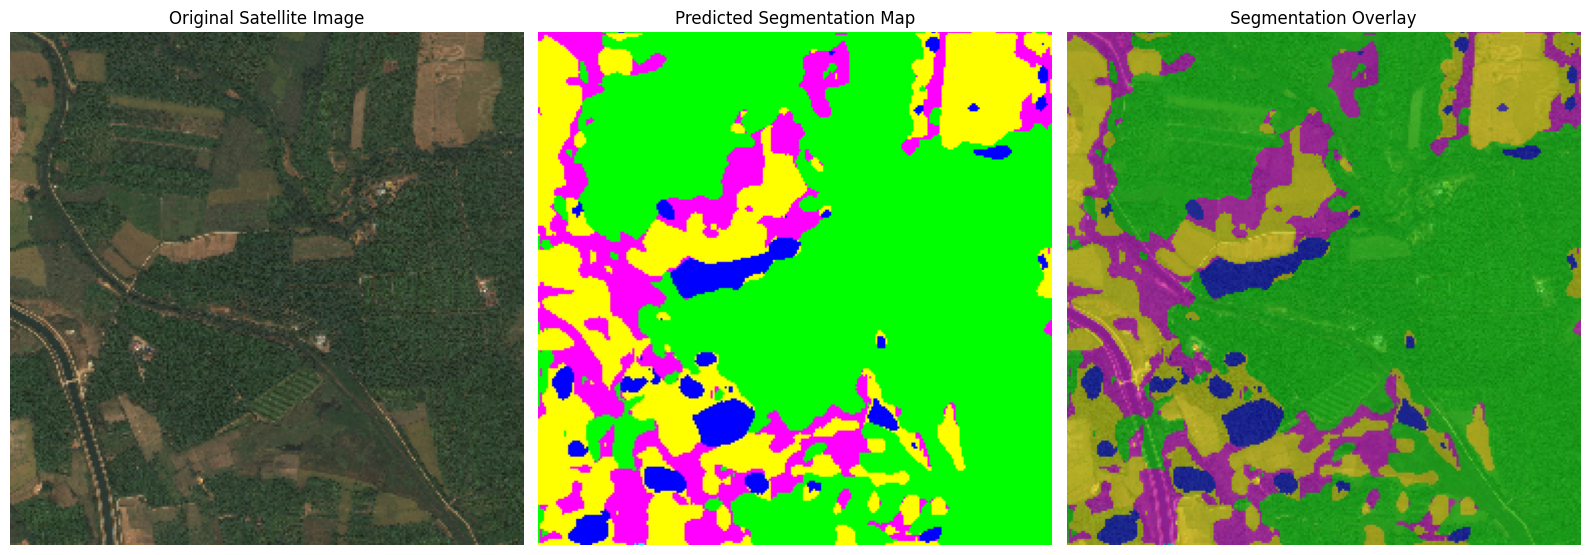

SEGMENTATION VISUALIZATION STATISTICS
Original resized image: (256, 256, 3)
Segmentation map: (256, 256, 3)
Overlay image: (256, 256, 3)

Overlay weights:
Original image: 55%
Segmentation map: 45%

Land-cover distribution:


,Land-Cover Class,Pixel Count,Percentage (%)
0,urban_land,4,0.01
1,agriculture_land,14628,22.32
2,rangeland,9691,14.79
3,forest_land,38262,58.38
4,water,2951,4.50
5,barren_land,0,0.00
6,unknown,0,0.00



Saved files:
Segmentation map: /content/drive/MyDrive/Satellite-Image-Project/reports/485061_sat_segmentation.png
Overlay: /content/drive/MyDrive/Satellite-Image-Project/reports/485061_sat_overlay.png

Segmentation visualization completed successfully!


In [ ]:

# Step 11: Generate and save segmentation overlay

# Create overlay using original resized image
segmentation_overlay = cv2.addWeighted(
    resized_original,
    0.55,
    segmentation_map,
    0.45,
    0
)

# Define output paths
segmentation_output_path = os.path.join(
    REPORT_DIR,
    "485061_sat_segmentation.png"
)

overlay_output_path = os.path.join(
    REPORT_DIR,
    "485061_sat_overlay.png"
)

# Save segmentation map
cv2.imwrite(
    segmentation_output_path,
    cv2.cvtColor(
        segmentation_map,
        cv2.COLOR_RGB2BGR
    )
)

# Save overlay
cv2.imwrite(
    overlay_output_path,
    cv2.cvtColor(
        segmentation_overlay,
        cv2.COLOR_RGB2BGR
    )
)

# Display images
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(resized_original)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(segmentation_map)
plt.title("Predicted Segmentation Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(segmentation_overlay)
plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

# Print numerical statistics for sharing
print("=" * 75)
print("SEGMENTATION VISUALIZATION STATISTICS")
print("=" * 75)

print("Original resized image:", resized_original.shape)
print("Segmentation map:", segmentation_map.shape)
print("Overlay image:", segmentation_overlay.shape)

print("\nOverlay weights:")
print("Original image: 55%")
print("Segmentation map: 45%")

print("\nLand-cover distribution:")
display(
    class_distribution_df[
        ["Land-Cover Class", "Pixel Count", "Percentage (%)"]
    ]
)

print("\nSaved files:")
print("Segmentation map:", segmentation_output_path)
print("Overlay:", overlay_output_path)

print("\nSegmentation visualization completed successfully!")


In [20]:

# Step 12: Generate final segmentation report and download results

import zipfile
import json

# Create report directory
os.makedirs(REPORT_DIR, exist_ok=True)

# Save land-cover distribution
class_csv_path = os.path.join(
    REPORT_DIR,
    "land_cover_distribution.csv"
)

class_distribution_df.to_csv(
    class_csv_path,
    index=False
)

# Save image quality statistics
quality_csv_path = os.path.join(
    REPORT_DIR,
    "image_quality_statistics.csv"
)

image_metrics_df.to_csv(
    quality_csv_path,
    index=False
)

# Prepare structured project report
segmentation_report = {
    "project": project_config["project_name"],
    "model": project_config["selected_model"],
    "input_image": os.path.basename(selected_image_path),
    "original_image_dimensions": list(original_image.shape),
    "model_input_dimensions": list(model_input.shape),
    "segmentation_dimensions": list(segmentation_map.shape),
    "total_pixels": int(total_pixels),
    "detected_classes": int(
        np.count_nonzero(
            class_distribution_df["Pixel Count"].values
        )
    ),
    "land_cover_distribution": [
        {
            "class_id": int(row["Class ID"]),
            "class_name": row["Land-Cover Class"],
            "pixel_count": int(row["Pixel Count"]),
            "percentage": float(row["Percentage (%)"])
        }
        for _, row in class_distribution_df.iterrows()
    ]
}

# Save JSON report
json_report_path = os.path.join(
    REPORT_DIR,
    "segmentation_report.json"
)

with open(json_report_path, "w") as file:
    json.dump(
        segmentation_report,
        file,
        indent=4
    )

# Generate readable text report
txt_report_path = os.path.join(
    REPORT_DIR,
    "segmentation_report.txt"
)

with open(txt_report_path, "w") as file:

    file.write("=" * 70 + "\n")
    file.write("SATELLITE IMAGE SEGMENTATION REPORT\n")
    file.write("=" * 70 + "\n\n")

    file.write(f"Model: {project_config['selected_model']}\n")
    file.write(f"Input image: {os.path.basename(selected_image_path)}\n")
    file.write(f"Original dimensions: {original_image.shape}\n")
    file.write(f"Segmentation dimensions: {segmentation_map.shape}\n")
    file.write(f"Total pixels: {total_pixels}\n\n")

    file.write("LAND-COVER DISTRIBUTION\n")
    file.write("-" * 70 + "\n")

    for _, row in class_distribution_df.iterrows():

        file.write(
            f"{row['Land-Cover Class']}: "
            f"{row['Pixel Count']} pixels "
            f"({row['Percentage (%)']}%)\n"
        )

    file.write("\nIMAGE QUALITY STATISTICS\n")
    file.write("-" * 70 + "\n")

    file.write(
        image_metrics_df.to_string(index=False)
    )

# Create ZIP package
zip_path = os.path.join(
    REPORT_DIR,
    "satellite_segmentation_results.zip"
)

result_files = [
    enhanced_output_path,
    segmentation_output_path,
    overlay_output_path,
    class_csv_path,
    quality_csv_path,
    json_report_path,
    txt_report_path
]

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in result_files:

        if os.path.exists(file_path):
            zip_file.write(
                file_path,
                arcname=os.path.basename(file_path)
            )

# Display final summary
print("=" * 75)
print("FINAL SEGMENTATION REPORT GENERATED")
print("=" * 75)

print("Input image:", os.path.basename(selected_image_path))
print("Model:", project_config["selected_model"])
print("Total pixels:", total_pixels)
print("Detected classes:", len(
    np.unique(predicted_mask)
))

print("\nLAND-COVER DISTRIBUTION")

display(
    class_distribution_df[
        ["Land-Cover Class", "Pixel Count", "Percentage (%)"]
    ]
)

print("\nGENERATED FILES")

for file_path in result_files:
    if os.path.exists(file_path):
        print("SUCCESS:", os.path.basename(file_path))

print("\nZIP PACKAGE:", zip_path)
print("ZIP SIZE:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

# Download ZIP package
files.download(zip_path)

print("\nFinal results package is ready for download!")


FINAL SEGMENTATION REPORT GENERATED
Input image: 119_sat.jpg
Model: Experimental U-Net
Total pixels: 65536
Detected classes: 5

LAND-COVER DISTRIBUTION


,Land-Cover Class,Pixel Count,Percentage (%)
0,urban_land,4,0.01
1,agriculture_land,14628,22.32
2,rangeland,9691,14.79
3,forest_land,38262,58.38
4,water,2951,4.50
5,barren_land,0,0.00
6,unknown,0,0.00



GENERATED FILES
SUCCESS: 485061_sat_enhanced.png
SUCCESS: 485061_sat_segmentation.png
SUCCESS: 485061_sat_overlay.png
SUCCESS: land_cover_distribution.csv
SUCCESS: image_quality_statistics.csv
SUCCESS: segmentation_report.json
SUCCESS: segmentation_report.txt

ZIP PACKAGE: /content/drive/MyDrive/Satellite-Image-Project/reports/satellite_segmentation_results.zip
ZIP SIZE: 13.27 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Final results package is ready for download!


In [60]:

from pathlib import Path
import cv2
import numpy as np
from PIL import Image

# Create a folder for paper figures
FIGURE_DIR = Path("/content/drive/MyDrive/Satellite-Image-Project/paper_figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Seven-class RGB colour mapping
CLASS_COLORS = {
    0: (0, 255, 255),      # Urban
    1: (255, 255, 0),      # Agriculture
    2: (255, 0, 255),      # Rangeland
    3: (0, 255, 0),        # Forest
    4: (0, 0, 255),        # Water
    5: (255, 255, 255),    # Barren
    6: (0, 0, 0)           # Unknown
}

# Resize original image to match model input dimensions
original_resized = cv2.resize(
    original_image,
    (256, 256),
    interpolation=cv2.INTER_AREA
)

# Save original image
Image.fromarray(
    original_resized.astype(np.uint8)
).save(FIGURE_DIR / "original_image.png")

# Save enhanced image
Image.fromarray(
    enhanced_image.astype(np.uint8)
).save(FIGURE_DIR / "enhanced_image.png")

# Convert predicted class IDs into RGB segmentation
segmentation_rgb = np.zeros((256, 256, 3), dtype=np.uint8)

for class_id, color in CLASS_COLORS.items():
    segmentation_rgb[predicted_mask == class_id] = color

# Save segmentation map
Image.fromarray(segmentation_rgb).save(
    FIGURE_DIR / "segmentation_map.png"
)

# Generate overlay
overlay = cv2.addWeighted(
    original_resized.astype(np.uint8),
    0.5,
    segmentation_rgb,
    0.5,
    0
)

# Save overlay
Image.fromarray(overlay).save(
    FIGURE_DIR / "overlay.png"
)

print("Paper figures saved successfully:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(path.name, "|", path.stat().st_size, "bytes")


Paper figures saved successfully:
enhanced_image.png | 105523 bytes
original_image.png | 111288 bytes
overlay.png | 94081 bytes
segmentation_map.png | 6280 bytes


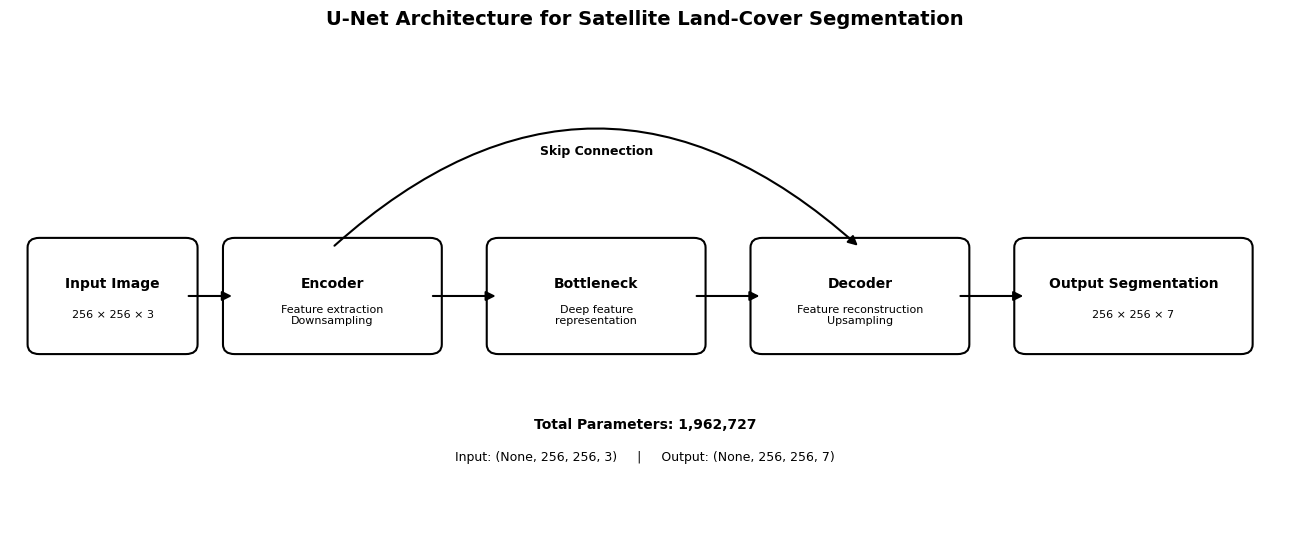

U-NET ARCHITECTURE DIAGRAM GENERATED
File: /content/drive/MyDrive/Satellite-Image-Project/paper_figures/unet_architecture.png
Input shape: (None, 256, 256, 3)
Output shape: (None, 256, 256, 7)
Total parameters: 1,962,727


In [62]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

# Output directory
FIGURE_DIR = Path(
    "/content/drive/MyDrive/Satellite-Image-Project/paper_figures"
)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load model if it is not already available
if "model" not in globals():
    import tensorflow as tf

    model_path = (
        "/content/drive/MyDrive/Satellite-Image-Project/models/"
        "best_rangeland_experimental_unet.keras"
    )

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

# Read actual model information
input_shape = model.input_shape
output_shape = model.output_shape
total_params = model.count_params()

# Create figure
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.set_xlim(0, 13)
ax.set_ylim(0, 6)
ax.axis("off")

# Function to draw architecture blocks
def draw_block(x, y, width, height, title, subtitle):
    block = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )

    ax.add_patch(block)

    ax.text(
        x + width / 2,
        y + height * 0.62,
        title,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        x + width / 2,
        y + height * 0.30,
        subtitle,
        ha="center",
        va="center",
        fontsize=8
    )

# Function to draw arrows
def draw_arrow(start, end, connectionstyle="arc3"):
    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=14,
        linewidth=1.5,
        color="black",
        connectionstyle=connectionstyle
    )
    ax.add_patch(arrow)

# Main U-Net flow
draw_block(0.3, 2.3, 1.5, 1.2,
           "Input Image", "256 × 256 × 3")

draw_block(2.3, 2.3, 2.0, 1.2,
           "Encoder", "Feature extraction\nDownsampling")

draw_block(5.0, 2.3, 2.0, 1.2,
           "Bottleneck", "Deep feature\nrepresentation")

draw_block(7.7, 2.3, 2.0, 1.2,
           "Decoder", "Feature reconstruction\nUpsampling")

draw_block(10.4, 2.3, 2.2, 1.2,
           "Output Segmentation", "256 × 256 × 7")

# Main flow arrows
draw_arrow((1.8, 2.9), (2.3, 2.9))
draw_arrow((4.3, 2.9), (5.0, 2.9))
draw_arrow((7.0, 2.9), (7.7, 2.9))
draw_arrow((9.7, 2.9), (10.4, 2.9))

# Conceptual skip connection
draw_arrow(
    (3.3, 3.5),
    (8.7, 3.5),
    connectionstyle="arc3,rad=-0.45"
)

ax.text(
    6.0, 4.65,
    "Skip Connection",
    ha="center",
    fontsize=9,
    fontweight="bold"
)

# Architecture information
ax.text(
    6.5, 1.25,
    f"Total Parameters: {total_params:,}",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

ax.text(
    6.5, 0.85,
    f"Input: {input_shape}     |     Output: {output_shape}",
    ha="center",
    fontsize=9
)

ax.set_title(
    "U-Net Architecture for Satellite Land-Cover Segmentation",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

# Save high-resolution image
output_path = FIGURE_DIR / "unet_architecture.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("=" * 60)
print("U-NET ARCHITECTURE DIAGRAM GENERATED")
print("=" * 60)
print("File:", output_path)
print("Input shape:", input_shape)
print("Output shape:", output_shape)
print("Total parameters:", f"{total_params:,}")


In [63]:

from pathlib import Path

FIGURE_DIR = Path(
    "/content/drive/MyDrive/Satellite-Image-Project/paper_figures"
)

required_images = [
    "unet_architecture.png",
    "original_image.png",
    "enhanced_image.png",
    "segmentation_map.png",
    "overlay.png"
]

print("PAPER FIGURE VERIFICATION")
print("=" * 55)

for filename in required_images:
    file_path = FIGURE_DIR / filename

    if file_path.exists():
        print(f"[OK] {filename} - {file_path.stat().st_size:,} bytes")
    else:
        print(f"[MISSING] {filename}")


PAPER FIGURE VERIFICATION
[OK] unet_architecture.png - 187,775 bytes
[OK] original_image.png - 111,288 bytes
[OK] enhanced_image.png - 105,523 bytes
[OK] segmentation_map.png - 6,280 bytes
[OK] overlay.png - 94,081 bytes
